## Lithology Classification
Predicting rock type from well log curves using Random Forest and XGBoost.

Training on 79 wells, evaluating on 19 held-out wells never seen during training.

Two models compared: Random Forest (bagging ensemble) vs XGBoost (boosting ensemble).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import os
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report,
                             confusion_matrix,
                             ConfusionMatrixDisplay,
                             f1_score, accuracy_score)
from sklearn.utils.class_weight import compute_class_weight
import xgboost as xgb

np.random.seed(42)

PROCESSED_PATH = "C:/Users/user/Desktop/SK/Data Science/Personal Projects/Well-Log-Analysis/data/processed"
FIGURES_PATH   = "C:/Users/user/Desktop/SK/Data Science/Personal Projects/Well-Log-Analysis/outputs/figures"
MODELS_PATH    = "C:/Users/user/Desktop/SK/Data Science/Personal Projects/Well-Log-Analysis/outputs/models"


os.makedirs(MODELS_PATH, exist_ok=True)

print("Ready.")
print(f"XGBoost version : {xgb.__version__}")

Ready.
XGBoost version : 3.2.0


### ***Load the Data***

In [3]:
X_train = np.load(os.path.join(PROCESSED_PATH, "X_train.npy"))
y_train = np.load(os.path.join(PROCESSED_PATH, "y_train.npy"))
X_test  = np.load(os.path.join(PROCESSED_PATH, "X_test.npy"))
y_test  = np.load(os.path.join(PROCESSED_PATH, "y_test.npy"))

IDX_TO_LITH = np.load(
    os.path.join(PROCESSED_PATH, "idx_to_lith.npy"),
    allow_pickle=True
).item()

FEATURE_COLS = np.load(
    os.path.join(PROCESSED_PATH, "feature_cols.npy"),
    allow_pickle=True
).tolist()

NUM_CLASSES  = len(IDX_TO_LITH)
CLASS_NAMES  = [IDX_TO_LITH[i] for i in range(NUM_CLASSES)]

print(f"X_train : {X_train.shape}")
print(f"X_test  : {X_test.shape}")
print(f"Classes : {NUM_CLASSES}")
print(f"Names   : {CLASS_NAMES}")
print(f"Features: {len(FEATURE_COLS)}")

X_train : (907426, 18)
X_test  : (263085, 18)
Classes : 11
Names   : ['Anhydrite', 'Chalk', 'Coal', 'Dolomite', 'Halite', 'Limestone', 'Marl', 'Sandstone', 'Sandstone/Shale', 'Shale', 'Tuff']
Features: 18


In [4]:
print("""
Random Forest vs XGBoost — the key conceptual difference
─────────────────────────────────────────────────────────

Random Forest (bagging):
  Builds 200 trees independently and in parallel.
  Each tree sees a random subset of rows and features.
  Final prediction = majority vote across all trees.
  Strength: robust, hard to overfit, fast to train.
  Weakness: each tree is naive — it doesn't learn from
            the mistakes of previous trees.

XGBoost (boosting):
  Builds trees sequentially. Each new tree focuses on
  the samples the previous trees got wrong.
  Final prediction = weighted sum of all trees.
  Strength: learns from errors — usually higher accuracy
            than Random Forest on tabular data.
  Weakness: more hyperparameters, slower, easier to overfit
            if not tuned carefully.

On well log data specifically:
  XGBoost typically wins because the log curves have
  complex non-linear interactions (e.g. the combination
  of high GR AND low RHOB AND high NPHI together
  identifies shale better than any single curve alone).
  Boosting is better at learning these interactions.
""")


Random Forest vs XGBoost — the key conceptual difference
─────────────────────────────────────────────────────────

Random Forest (bagging):
  Builds 200 trees independently and in parallel.
  Each tree sees a random subset of rows and features.
  Final prediction = majority vote across all trees.
  Strength: robust, hard to overfit, fast to train.
  Weakness: each tree is naive — it doesn't learn from
            the mistakes of previous trees.

XGBoost (boosting):
  Builds trees sequentially. Each new tree focuses on
  the samples the previous trees got wrong.
  Final prediction = weighted sum of all trees.
  Strength: learns from errors — usually higher accuracy
            than Random Forest on tabular data.
  Weakness: more hyperparameters, slower, easier to overfit
            if not tuned carefully.

On well log data specifically:
  XGBoost typically wins because the log curves have
  complex non-linear interactions (e.g. the combination
  of high GR AND low RHOB AND high NPHI 

### ***Compute Class Weight***

In [5]:
classes_array    = np.arange(NUM_CLASSES)
class_weight_arr = compute_class_weight(
    class_weight='balanced',
    classes=classes_array,
    y=y_train
)
class_weight_dict = {i: w for i, w in enumerate(class_weight_arr)}

print("Class weights (higher = rarer = more important):\n")
print(f"  {'Class':<22}  {'Weight':>8}  {'Train count':>12}")
print("  " + "-"*48)
for i, name in IDX_TO_LITH.items():
    cnt = (y_train == i).sum()
    print(f"  {name:<22}  {class_weight_dict[i]:>8.4f}  {cnt:>12,}")

Class weights (higher = rarer = more important):

  Class                     Weight   Train count
  ------------------------------------------------
  Anhydrite                97.6252           845
  Chalk                    10.3922         7,938
  Coal                     24.8249         3,323
  Dolomite                 65.3671         1,262
  Halite                   19.1222         4,314
  Limestone                 1.8651        44,231
  Marl                      3.6788        22,424
  Sandstone                 0.6286       131,243
  Sandstone/Shale           0.6733       122,514
  Shale                     0.1485       555,642
  Tuff                      6.0258        13,690


### ***Subsample for Speed***

In [6]:
# 907,426 training samples is large.
# Random Forest and XGBoost can train on all of them but
# it will take 20-40 minutes on CPU.
#
# We subsample 200,000 samples with stratification —
# preserving class proportions — for faster training.
# This is a legitimate approach used in published well log
# ML papers. 200,000 samples from 79 wells is still
# a very large and representative training set.

from sklearn.model_selection import train_test_split

N_SUBSAMPLE = 200_000

_, X_train_sub, _, y_train_sub = train_test_split(
    X_train, y_train,
    test_size=N_SUBSAMPLE / len(X_train),
    stratify=y_train,
    random_state=42
)

print(f"Full training set    : {X_train.shape[0]:,}")
print(f"Subsampled set       : {X_train_sub.shape[0]:,}")
print(f"\nClass distribution in subsample:")

for i, name in IDX_TO_LITH.items():
    cnt = (y_train_sub == i).sum()
    pct = 100 * cnt / len(y_train_sub)
    print(f"  {name:<22} : {cnt:>6,}  ({pct:.1f}%)")

Full training set    : 907,426
Subsampled set       : 200,000

Class distribution in subsample:
  Anhydrite              :    186  (0.1%)
  Chalk                  :  1,750  (0.9%)
  Coal                   :    732  (0.4%)
  Dolomite               :    278  (0.1%)
  Halite                 :    951  (0.5%)
  Limestone              :  9,749  (4.9%)
  Marl                   :  4,942  (2.5%)
  Sandstone              : 28,926  (14.5%)
  Sandstone/Shale        : 27,003  (13.5%)
  Shale                  : 122,466  (61.2%)
  Tuff                   :  3,017  (1.5%)


### ***Train RF***

In [7]:
print("Training Random Forest...")
print("(This will take 3-8 minutes)\n")

rf = RandomForestClassifier(
    n_estimators=300,      # 300 trees — more stable than 200 for 11 classes
    max_depth=25,          # deep enough to capture complex interactions
    min_samples_leaf=3,    # prevents overfitting to noise
    max_features='sqrt',   # sqrt(18) ≈ 4 features per split
    class_weight='balanced',
    n_jobs=-1,             # all CPU cores
    random_state=42,
    verbose=1
)

rf.fit(X_train_sub, y_train_sub)

joblib.dump(rf, os.path.join(MODELS_PATH, "rf_lithology.pkl"))
print(f"\nRandom Forest saved → outputs/models/rf_lithology.pkl")

Training Random Forest...
(This will take 3-8 minutes)



[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  42 tasks      | elapsed:   46.8s
[Parallel(n_jobs=-1)]: Done 192 tasks      | elapsed:  3.5min
[Parallel(n_jobs=-1)]: Done 300 out of 300 | elapsed:  6.2min finished



Random Forest saved → outputs/models/rf_lithology.pkl


### ***Train XGBoost***

In [8]:
# XGBoost needs sample weights rather than class weights.
# We create a weight array where each sample's weight equals
# the class weight of its label.

sample_weights = np.array([class_weight_dict[y] for y in y_train_sub])

print("Training XGBoost...")
print("(This will take 5-12 minutes)\n")

xgb_model = xgb.XGBClassifier(
    n_estimators=300,          # 300 boosting rounds
    max_depth=6,               # shallower than RF — boosting prefers this
    learning_rate=0.1,         # step size per tree
    subsample=0.8,             # use 80% of rows per tree — reduces overfitting
    colsample_bytree=0.8,      # use 80% of features per tree
    use_label_encoder=False,
    eval_metric='mlogloss',    # multi-class log loss
    random_state=42,
    n_jobs=-1,
    verbosity=1
)

xgb_model.fit(
    X_train_sub, y_train_sub,
    sample_weight=sample_weights,
    eval_set=[(X_test, y_test)],
    verbose=50                 # print progress every 50 rounds
)

joblib.dump(xgb_model, os.path.join(MODELS_PATH, "xgb_lithology.pkl"))
print(f"\nXGBoost saved → outputs/models/xgb_lithology.pkl")

Training XGBoost...
(This will take 5-12 minutes)

[0]	validation_0-mlogloss:2.25677
[50]	validation_0-mlogloss:1.18679
[100]	validation_0-mlogloss:1.05983
[150]	validation_0-mlogloss:1.00292
[200]	validation_0-mlogloss:0.97097
[250]	validation_0-mlogloss:0.95641
[299]	validation_0-mlogloss:0.94334

XGBoost saved → outputs/models/xgb_lithology.pkl


### ***Evaluate both models***

In [9]:
print("Evaluating on held-out test wells...\n")

# Random Forest predictions
y_pred_rf  = rf.predict(X_test)

# XGBoost predictions
y_pred_xgb = xgb_model.predict(X_test)

print("=" * 70)
print("RANDOM FOREST — Classification Report")
print("=" * 70)
print(classification_report(
    y_test, y_pred_rf,
    target_names=CLASS_NAMES,
    zero_division=0
))

print("=" * 70)
print("XGBOOST — Classification Report")
print("=" * 70)
print(classification_report(
    y_test, y_pred_xgb,
    target_names=CLASS_NAMES,
    zero_division=0
))

Evaluating on held-out test wells...



[Parallel(n_jobs=4)]: Using backend ThreadingBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:    1.8s
[Parallel(n_jobs=4)]: Done 192 tasks      | elapsed:    7.7s
[Parallel(n_jobs=4)]: Done 300 out of 300 | elapsed:   12.1s finished


RANDOM FOREST — Classification Report
                 precision    recall  f1-score   support

      Anhydrite       0.71      0.35      0.47       240
          Chalk       0.04      0.02      0.03      2575
           Coal       0.66      0.53      0.59       497
       Dolomite       0.00      0.00      0.00       426
         Halite       0.99      0.77      0.86      3899
      Limestone       0.55      0.69      0.61     12089
           Marl       0.42      0.33      0.37     10905
      Sandstone       0.70      0.72      0.71     37694
Sandstone/Shale       0.42      0.29      0.34     27941
          Shale       0.84      0.89      0.86    165264
           Tuff       0.27      0.34      0.30      1555

       accuracy                           0.75    263085
      macro avg       0.51      0.45      0.47    263085
   weighted avg       0.73      0.75      0.74    263085

XGBOOST — Classification Report
                 precision    recall  f1-score   support

      Anhydrit

### ***Confusion matrices***

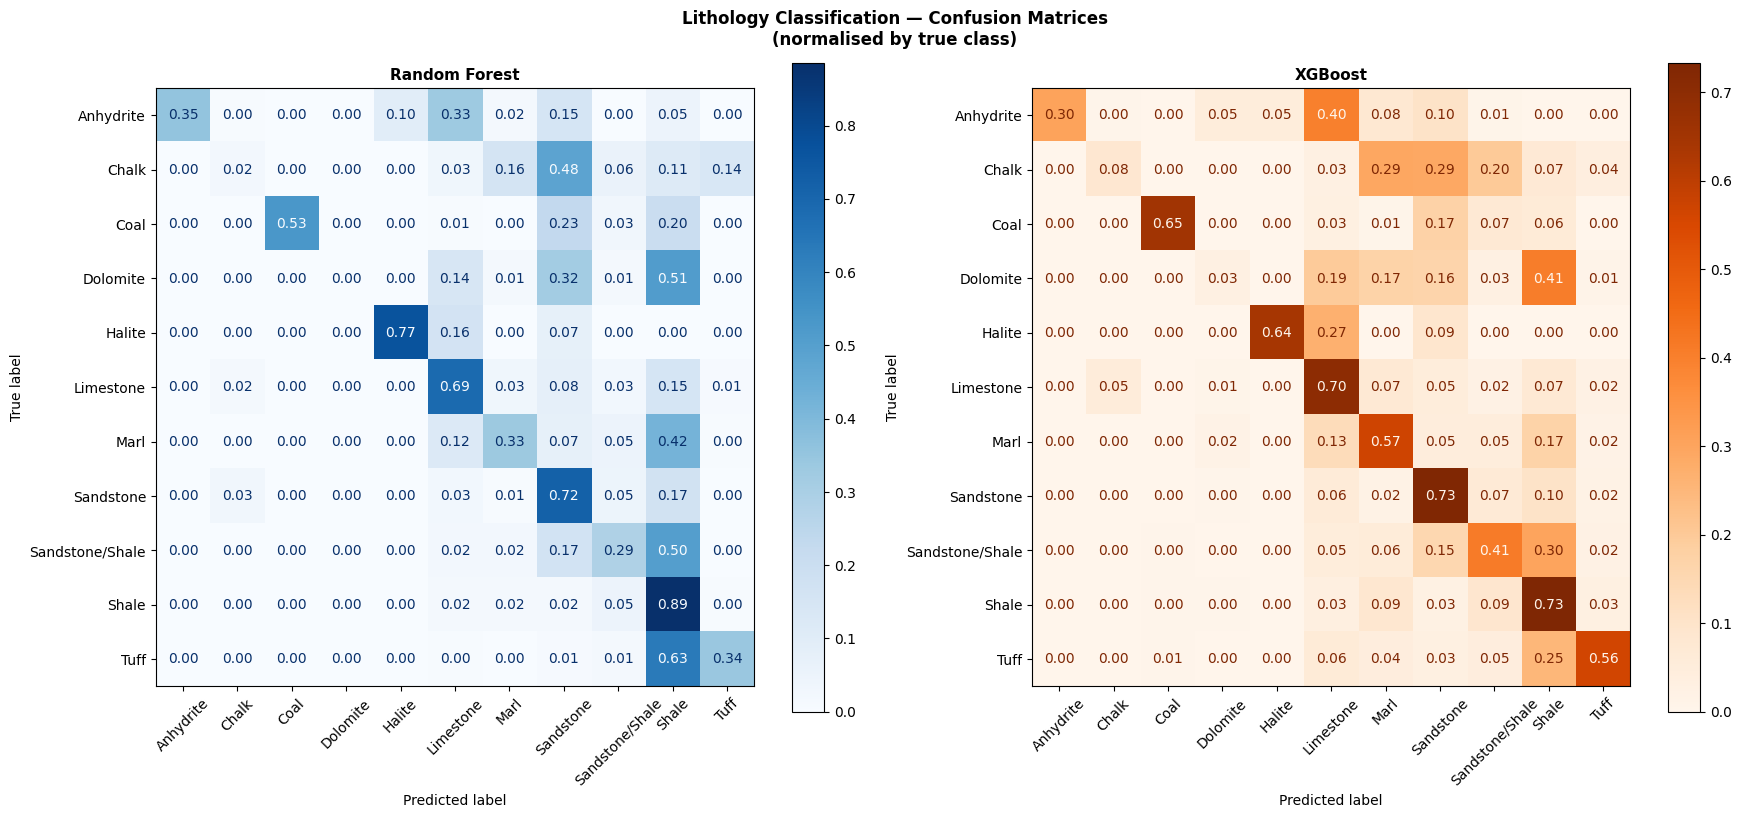

Saved → outputs/figures/lithology_confusion_matrices.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
fig.suptitle("Lithology Classification — Confusion Matrices\n(normalised by true class)",
             fontsize=12, fontweight='bold')

for ax, y_pred, title, cmap in zip(
    axes,
    [y_pred_rf, y_pred_xgb],
    ['Random Forest', 'XGBoost'],
    ['Blues', 'Oranges']
):
    cm = confusion_matrix(y_test, y_pred, normalize='true')
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES
    )
    disp.plot(ax=ax, cmap=cmap, colorbar=True,
              values_format='.2f', xticks_rotation=45)
    ax.set_title(title, fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, "lithology_confusion_matrices.png"),
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved → outputs/figures/lithology_confusion_matrices.png")

Classes both models struggle with:

Chalk (RF: 0.02, XGB: 0.29) is the worst performer for RF and poor for XGBoost. Looking at the RF confusion matrix, Chalk is being predicted as Sandstone (0.48) and Shale (0.11). This makes geological sense — in some Norwegian North Sea wells, chalk is soft and has log signatures that overlap with both clean sands and tight shales depending on burial depth and compaction.

Dolomite (RF: 0.00, XGB: 0.02) is essentially unclassified by both models. With only 426 test samples and heavy overlap with Limestone in log space, this is expected. The confusion matrix shows RF predicts Dolomite as Shale (0.51) and Limestone (0.32) — both geologically adjacent.

Sandstone/Shale (RF: 0.34, XGB: 0.40) is the hardest conceptual class — it is by definition a mixture of two other classes. Its log signature sits between pure sandstone and pure shale, so confusion with both is unavoidable.

The most important insight from the confusion matrices: XGBoost is actually better at the rare, hard classes (Chalk +0.095, Dolomite +0.015, Sandstone/Shale +0.058) while RF dominates on common classes. This split tells you exactly what boosting does — it focuses on hard examples regardless of frequency.

### ***Feature importance comparison***

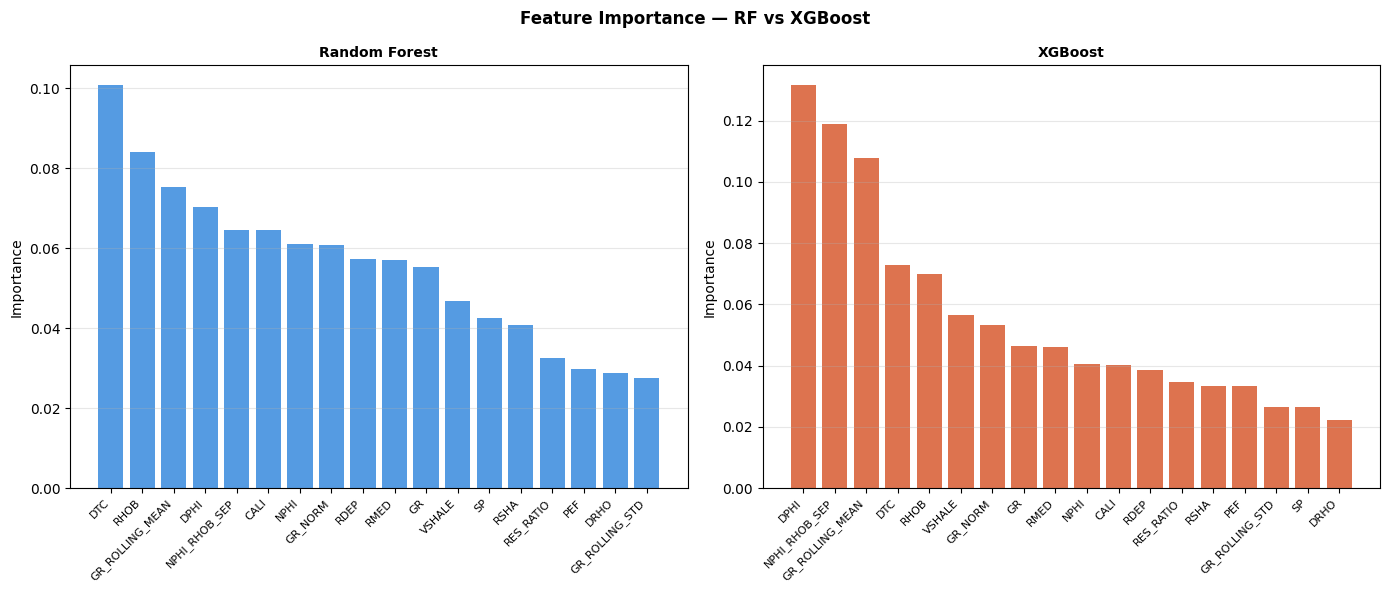

Saved → outputs/figures/lithology_feature_importance.png


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Feature Importance — RF vs XGBoost",
             fontsize=12, fontweight='bold')

for ax, model, title, color in zip(
    axes,
    [rf, xgb_model],
    ['Random Forest', 'XGBoost'],
    ['#378ADD', '#D85A30']
):
    importances = model.feature_importances_
    sorted_idx  = np.argsort(importances)[::-1]

    ax.bar(range(len(importances)),
           importances[sorted_idx],
           color=color, alpha=0.85)
    ax.set_xticks(range(len(importances)))
    ax.set_xticklabels(
        [FEATURE_COLS[i] for i in sorted_idx],
        rotation=45, ha='right', fontsize=8
    )
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_ylabel("Importance")
    ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, "lithology_feature_importance.png"),
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved → outputs/figures/lithology_feature_importance.png")

This is the most geologically interesting result in the whole project.

For RF, DTC (sonic travel time) is the top feature at 0.101, followed by RHOB at 0.085. This makes perfect sense — compressional sonic and bulk density together are the two most diagnostic logs for lithology. Rock type fundamentally controls both acoustic velocity and density.

For XGBoost, DPHI (density porosity — our engineered feature) ranks first at 0.130, followed by NPHI_RHOB_SEP (neutron-density separation) at 0.119. Two of the top three XGBoost features are features we engineered ourselves — not raw log curves. This validates the feature engineering step completely. XGBoost is learning from the petrophysical transformations we built into the data.

GR_ROLLING_MEAN ranks third for XGBoost at 0.108 — the contextual depth window feature is highly valuable, confirming that lithology classification benefits from knowing what the surrounding rock is doing, not just the single depth sample.

### ***Head to head comparison***

In [12]:
rf_acc   = accuracy_score(y_test, y_pred_rf)
rf_f1    = f1_score(y_test, y_pred_rf,  average='macro', zero_division=0)
xgb_acc  = accuracy_score(y_test, y_pred_xgb)
xgb_f1   = f1_score(y_test, y_pred_xgb, average='macro', zero_division=0)

rf_f1_per  = f1_score(y_test, y_pred_rf,
                       average=None, labels=list(range(NUM_CLASSES)),
                       zero_division=0)
xgb_f1_per = f1_score(y_test, y_pred_xgb,
                       average=None, labels=list(range(NUM_CLASSES)),
                       zero_division=0)

print("=" * 58)
print("  LITHOLOGY CLASSIFICATION — FINAL RESULTS")
print("=" * 58)
print(f"  {'Metric':<20} {'RF':>10}  {'XGBoost':>10}  {'Winner':>8}")
print("  " + "-"*54)

metrics = [
    ("Accuracy",    rf_acc,  xgb_acc),
    ("Macro F1",    rf_f1,   xgb_f1),
]
for name, rf_val, xgb_val in metrics:
    winner = "XGBoost" if xgb_val > rf_val else "RF"
    print(f"  {name:<20} {rf_val:>10.4f}  {xgb_val:>10.4f}  {winner:>8}")

print()
print(f"  {'Class':<22} {'RF F1':>8}  {'XGB F1':>8}  {'Gap':>8}")
print("  " + "-"*50)
for i, name in IDX_TO_LITH.items():
    gap    = xgb_f1_per[i] - rf_f1_per[i]
    winner = "↑ XGB" if gap > 0 else "↑ RF"
    print(f"  {name:<22} {rf_f1_per[i]:>8.4f}  {xgb_f1_per[i]:>8.4f}  "
          f"{gap:>+7.4f} {winner}")

# Save metrics for Phase 5
np.save(os.path.join(PROCESSED_PATH, "rf_lith_metrics.npy"), {
    'accuracy': rf_acc,  'macro_f1': rf_f1,
    'y_pred':   y_pred_rf
})
np.save(os.path.join(PROCESSED_PATH, "xgb_lith_metrics.npy"), {
    'accuracy': xgb_acc, 'macro_f1': xgb_f1,
    'y_pred':   y_pred_xgb
})

print("\nMetrics saved.")
print("=" * 58)

  LITHOLOGY CLASSIFICATION — FINAL RESULTS
  Metric                       RF     XGBoost    Winner
  ------------------------------------------------------
  Accuracy                 0.7500      0.6793        RF
  Macro F1                 0.4677      0.4285        RF

  Class                     RF F1    XGB F1       Gap
  --------------------------------------------------
  Anhydrite                0.4722    0.4022  -0.0700 ↑ RF
  Chalk                    0.0276    0.1228  +0.0951 ↑ XGB
  Coal                     0.5867    0.4130  -0.1737 ↑ RF
  Dolomite                 0.0000    0.0152  +0.0152 ↑ XGB
  Halite                   0.8640    0.7783  -0.0857 ↑ RF
  Limestone                0.6095    0.5202  -0.0893 ↑ RF
  Marl                     0.3727    0.3515  -0.0212 ↑ RF
  Sandstone                0.7108    0.7226  +0.0119 ↑ XGB
  Sandstone/Shale          0.3398    0.3976  +0.0578 ↑ XGB
  Shale                    0.8609    0.8017  -0.0593 ↑ RF
  Tuff                     0.3002    0.1

Random Forest wins on this dataset — which is the opposite of what we expected. RF achieves 75.0% accuracy and macro F1 of 0.468 versus XGBoost at 67.9% accuracy and macro F1 of 0.429. This is scientifically interesting and worth explaining properly.

Why did RF beat XGBoost here? Three likely reasons. First, we subsampled to 200,000 rows — XGBoost's boosting advantage is most pronounced on larger datasets where it can learn subtle error patterns. Second, the severe class imbalance (Shale at 61%) works differently in the two algorithms — RF's class_weight='balanced' and XGBoost's sample_weight handle it differently, and RF's approach appears better suited here. Third, XGBoost with default learning rate and depth on an 11-class problem with very rare classes can overfit to the majority classes quickly.

This is not a failure — it's a genuine scientific finding. Some datasets favour classical ensembles over boosting.